## Ejemplo 5: Clasificación con una Red Neuronal

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import tensorflow.keras as keras
import tensorflow.keras.layers as layers

### 1. Lectura y pre-procesamiento de datos

In [2]:
# Importar base de datos MNIST
mnist = keras.datasets.mnist

Dividir datos en entrenamiento (train) y prueba (test)

In [3]:
(X_train, Y_train), (X_test, Y_test) = mnist.load_data()

11493376/11490434 [==============================] - 0s 0us/step


Normalizar los datos (de 0-255 a 0-1)

In [4]:
X_train, X_test = X_train/255.0, X_test/255.0

In [5]:
# Tamaño de cada imagen
print("El tamaño de cada imagen es:", X_train[0].shape)

El tamaño de cada imagen es: (28, 28)


Mostrar los datos (imágenes) solo para inspección visual

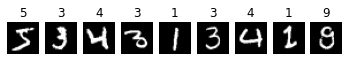

In [6]:
# Se muestra los números de imágenes que se encuentran en la siguiente lista
num_imagenes = [0, 10, 20, 30, 40, 50, 60, 70, 80]

for i in range(len(num_imagenes)):
    plt.subplot(1, len(num_imagenes), i+1)
    Xi = X_train[num_imagenes[i],:,:]
    yi = Y_train[num_imagenes[i]]
    plt.imshow(Xi, cmap='gray')
    plt.title(yi); plt.axis('off')

### 2. Entrenamiento: Red Neuronal

Inicializar el modelo con la siguiente arquitectura:
* La capa de entrada es "Flatten": las imágenes de (28x28) se convierten en vectores ("flatten") 
* La capa oculta es una capa "Densa": con 512 neuronas y con activación de tipo ReLU 
* La capa de salida es una capa "Densa": con 10 neuronas (porque hay 10 clases) y activación "softmax"

In [7]:
modelo = keras.models.Sequential([
    layers.Flatten(input_shape=(28,28)),
    layers.Dense(512, activation='relu'),
    layers.Dense(10, activation='softmax')
])

Compilar el modelo
* Se utiliza el optimizador "adam"
* El costo se define como entropía cruzada categórica ("con base en el logaritmo del error")
* Como métrica se utiliza la exactitud (accuracy)

In [8]:
modelo.compile(optimizer='adam',
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy'])

Se crea un clase `callback` para que el entrenamiento termine cuando se cumpla la siguiente condición:
* Cuando la exactitud sea mayor a 0.98

La clase siempre hereda la clase base Callback de Keras
* El miembro `on_epoch_end` se ejecuta cada vez que se termine una época (epoch)
* Se verifica si 'accuracy' es mayor que 0.98 y de serlo se termina el entrenamiento (`stop_training`)

In [9]:
class MyCallback(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs={}):
        if (logs.get('accuracy') > 0.98):
            print("\n\n98% de Exactitud alcanzada ... deteniendo\n")
            self.model.stop_training = True

# Instancia de la clase Callback
mycb = MyCallback()

# Entranamiento del modelo usando 20 épocas y el Callback para detener el entrenamiento
modelo.fit(X_train, Y_train, epochs=20, callbacks=[mycb])

Epoch 1/20
1875/1875 [==============================] - 3s 2ms/step - loss: 0.2015 - accuracy: 0.9412
Epoch 2/20
1875/1875 [==============================] - 3s 2ms/step - loss: 0.0785 - accuracy: 0.9763
Epoch 3/20
1865/1875 [============================>.] - ETA: 0s - loss: 0.0509 - accuracy: 0.9840

98% de Exactitud alcanzada ... deteniendo

1875/1875 [==============================] - 3s 2ms/step - loss: 0.0509 - accuracy: 0.9840


### 3. Evaluación

Exactitud en el conjunto de entrenamiento

In [10]:
# Usando el conjunto de entrenamiento
res = modelo.evaluate(X_train, Y_train, verbose=False)
print("En conjunto de entrenamiento: Costo (loss) = {:.3f}, exactitud (accuracy) = {:.3f}".format(res[0], res[1]))

En conjunto de entrenamiento: Costo (loss) = 0.037, exactitud (accuracy) = 0.988


Exactitud en el conjunto de prueba

In [11]:
# Usando el conjunto de prueba
res = modelo.evaluate(X_test, Y_test, verbose=False)
print("En conjunto de prueba (test): Costo (loss) = {:.3f}, exactitud (accuracy) = {:.3f}".format(res[0], res[1]))

En conjunto de prueba (test): Costo (loss) = 0.076, exactitud (accuracy) = 0.976


### 4. Predicción

In [12]:
# Predicción para las imágenes de prueba con los siguientes índices
num_imagenes = [0, 10, 20, 30, 40, 50, 60, 70, 80]
X = X_test[num_imagenes,:,:]

# Predicciones en formato "salida de softmax" (10 elementos, cada uno indica una probabilidad)
ypred = modelo.predict(X)
# Conversión a número que se predice (de 0 a 9)
ypred = np.argmax(ypred, axis=1)

Mostrar las imágenes predichas

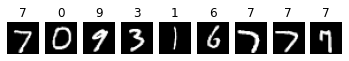

In [13]:
# Mostrar las imágenes que se encuentran en la siguiente lista
for i in range(len(num_imagenes)):
    plt.subplot(1, len(num_imagenes), i+1)
    plt.imshow(X[i,:,:], cmap='gray')
    plt.title(ypred[i])
    plt.axis('off')